In [21]:
import torch
import torch.nn.functional as F
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [22]:
import os
import re
import glob
import pandas as pd
import matplotlib.pyplot as plt

In [23]:
from tqdm import tqdm
import gymnasium as gym
import gym_donkeycar
import numpy as np
conf = {
    "host": "127.0.0.1",         # 模擬器主機
    "port": 9091,                # 模擬器連接埠
    "log_level": 20,             # logging.INFO
    "level": "generated_track",  # 場景名稱
    "cam_resolution": (120, 160, 3),  # camera resolution (H,W,D)
    "max_cte": 2.0,              # max cross track error
    "body_style": "donkey",
    "car_name":"kghs",
    "body_rgb": (255, 255, 255),
    "font_size": 20
}

In [24]:
class ImageEnv(gym.Wrapper):
    def __init__(self,env,stack_frames=4,delay_op=5):
        super(ImageEnv,self).__init__(env)
        self.stack_frames=stack_frames
        self.delay_op=delay_op
        steer_levels=np.linspace(-1.0,1.0,20,dtype=np.float32)
        strottle_levels=np.linspace(0.0,1.0,20,dtype=np.float32)
        self._action_table=np.array([(s,t) for s in steer_levels for t in strottle_levels],dtype=np.float32)
        self.action_space=gym.spaces.Discrete(self._action_table.shape[0])
    def reset(self):
        s,info=self.env.reset()
        for i in range(self.delay_op):
            s,r,done,stop,info=self.env.step(np.array([0.0,0.0]))
            img=s
            s=(s.dot([0.299,0.587,0.114])/255)-0.5
            self.stacked_state=np.tile( s , (self.stack_frames,1,1) )#(4,120,160)
        return self.stacked_state,img
    def step(self,action):
        reward=0
        for _ in range(self.stack_frames):
            s,r,done,stop,info=self.env.step(self._action_table[action])
            img=s
            s=(s.dot([0.299,0.587,0.114])/255)-0.5 
            reward+=r
            if done or stop:break
            self.stacked_state=np.concatenate( (self.stacked_state[1:] , s[np.newaxis] ) , axis=0 )
        return self.stacked_state,reward,done,stop,img

In [25]:
class DQN(torch.nn.Module):
    def __init__(self,n_act):
        super(DQN,self).__init__()
        self.conv1=torch.nn.Conv2d(4,16,8,4)#輸入色頻、輸出色頻、卷積核大小、步長=>16x29x39
        self.conv2=torch.nn.Conv2d(16,32,4,2)#輸入色頻、輸出色頻、卷積核大小、步長=>32x13x18
        self.fc1=torch.nn.Linear(7488,512)
        self.A=torch.nn.Linear(512,n_act)
        self.V=torch.nn.Linear(512,1)
    def forward(self,x):
        x=F.relu( self.conv1(x) )
        x=F.relu( self.conv2(x) )
        x=x.reshape((-1,7488))
        x=F.relu(self.fc1(x))
        A=self.A(x)
        V=self.V(x)
        return A+V-torch.mean(A,dim=-1,keepdims=True)

In [26]:
# 評估 Agent
class EvaluatorAgent:
    def __init__(self, env):
        self.env = env
        self.n_act = self.env.action_space.n
        self.model = DQN(self.n_act).to(device)
        self.model.eval()

    def load_weights(self, weight_path):
        """載入指定的 checkpoint 權重"""
        state_dict = torch.load(weight_path, map_location=device)
        self.model.load_state_dict(state_dict)

    def select_action(self, state):
        """完全使用 Greedy 策略 (epsilon=0)"""
        with torch.no_grad():
            state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)
            return torch.argmax(self.model(state_tensor)).item()

    def evaluate(self, num_episodes=5):
        """執行固定次數的回合測試並統計數據"""
        episode_rewards = []
        episode_steps = []

        for _ in range(num_episodes):
            s, _ = self.env.reset()
            total_reward = 0
            steps = 0
            while True:
                a = self.select_action(s)
                s, r, done, stop, _ = self.env.step(a)
                total_reward += r
                steps += 1
                if done or stop:
                    break
            episode_rewards.append(total_reward)
            episode_steps.append(steps)

        return {
            "mean_reward": float(np.mean(episode_rewards)),
            "std_reward": float(np.std(episode_rewards)),
            "mean_steps": float(np.mean(episode_steps)),
            "max_reward": float(np.max(episode_rewards))
        }

INFO:gym_donkeycar.core.client:connecting to 127.0.0.1:9091 


starting DonkeyGym env
Setting default: start_delay 5.0
Setting default: frame_skip 1
Setting default: steer_limit 1.0
Setting default: throttle_min 0.0
Setting default: throttle_max 1.0
loading scene generated_track


INFO:gym_donkeycar.envs.donkey_sim:on need car config
INFO:gym_donkeycar.envs.donkey_sim:sending car config.
INFO:gym_donkeycar.envs.donkey_sim:sim started!


找到 40 個 checkpoint，開始批次測試...
[DQN_499.pt] -> 平均得分: 28.88 ± 0.02, 平均存活步數: 11.0
[DQN_999.pt] -> 平均得分: 31.72 ± 0.01, 平均存活步數: 13.0
[DQN_1499.pt] -> 平均得分: 30.47 ± 0.01, 平均存活步數: 11.0
[DQN_1999.pt] -> 平均得分: 27.02 ± 0.07, 平均存活步數: 14.0
[DQN_2499.pt] -> 平均得分: 43.24 ± 0.87, 平均存活步數: 15.6
[DQN_2999.pt] -> 平均得分: 8.69 ± 0.00, 平均存活步數: 7.0
[DQN_3499.pt] -> 平均得分: 7.19 ± 0.00, 平均存活步數: 5.0
[DQN_3999.pt] -> 平均得分: 23.59 ± 0.00, 平均存活步數: 12.0
[DQN_4499.pt] -> 平均得分: 27.36 ± 10.54, 平均存活步數: 11.6
[DQN_4999.pt] -> 平均得分: 47.20 ± 0.00, 平均存活步數: 11.0
[DQN_5499.pt] -> 平均得分: 23.18 ± 0.00, 平均存活步數: 12.0
[DQN_5999.pt] -> 平均得分: 37.23 ± 4.33, 平均存活步數: 12.2
[DQN_6499.pt] -> 平均得分: 94.08 ± 26.75, 平均存活步數: 19.2
[DQN_6999.pt] -> 平均得分: 34.79 ± 0.00, 平均存活步數: 11.0
[DQN_7499.pt] -> 平均得分: 82.55 ± 33.03, 平均存活步數: 18.0
[DQN_7999.pt] -> 平均得分: 55.03 ± 8.47, 平均存活步數: 14.4
[DQN_8499.pt] -> 平均得分: 53.78 ± 25.19, 平均存活步數: 15.0
[DQN_8999.pt] -> 平均得分: 54.45 ± 0.00, 平均存活步數: 14.0
[DQN_9499.pt] -> 平均得分: 46.31 ± 0.00, 平均存活步數: 14.0
[DQN_9999.pt] -> 平均得分: 

INFO:gym_donkeycar.envs.donkey_sim:New lap time: 11.29 seconds


[DQN_17499.pt] -> 平均得分: 124.12 ± 139.35, 平均存活步數: 24.0
[DQN_17999.pt] -> 平均得分: 148.33 ± 50.31, 平均存活步數: 28.0
[DQN_18499.pt] -> 平均得分: 48.15 ± 5.28, 平均存活步數: 14.4
[DQN_18999.pt] -> 平均得分: 44.05 ± 1.84, 平均存活步數: 11.8
[DQN_19499.pt] -> 平均得分: 50.12 ± 7.03, 平均存活步數: 13.6
[DQN_19999.pt] -> 平均得分: 55.17 ± 10.26, 平均存活步數: 13.8

測試數據已儲存至: dueling_dqn_checkpoint_evaluation.csv
評估曲線圖已儲存至: dueling_dqn_evaluation_curve.png


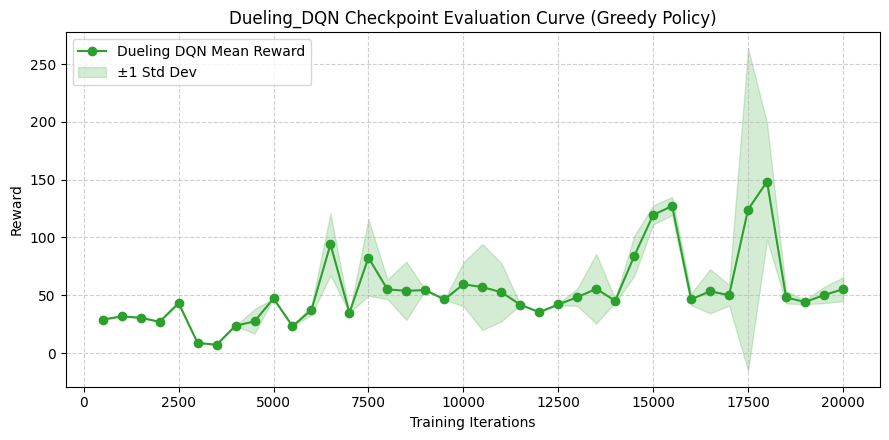

In [27]:
if __name__ == "__main__":
    # 建立環境與評估物件
    env = gym.make("donkey-generated-track-v0", conf=conf, render_mode="rgb_array")
    env = ImageEnv(env)
    evaluator = EvaluatorAgent(env)

    weight_files = glob.glob("DQN_*.pt")

    # 依照檔名中的數字順序排序
    def get_iteration(filename):
        match = re.search(r'DQN_(\d+)\.pt', filename)
        return int(match.group(1)) if match else -1

    weight_files = [f for f in weight_files if get_iteration(f) >= 0]
    weight_files.sort(key=get_iteration)

    results = []
    print(f"找到 {len(weight_files)} 個 checkpoint，開始批次測試...")
    for file_path in weight_files:
        it = get_iteration(file_path)
        evaluator.load_weights(file_path)
        
        # 每個 checkpoint 跑 5 回合取平均與標準差
        metrics = evaluator.evaluate(num_episodes=5)
        
        print(f"[{file_path}] -> 平均得分: {metrics['mean_reward']:.2f} ± {metrics['std_reward']:.2f}, 平均存活步數: {metrics['mean_steps']:.1f}")
        
        results.append({
            "Iteration": it + 1,
            "Checkpoint": file_path,
            "MeanReward": metrics["mean_reward"],
            "StdReward": metrics["std_reward"],
            "MeanSteps": metrics["mean_steps"],
            "MaxReward": metrics["max_reward"]
        })

    # 輸出評估報表 CSV
    df = pd.DataFrame(results)
    csv_filename = "dueling_dqn_checkpoint_evaluation.csv"
    df.to_csv(csv_filename, index=False, encoding="utf-8-sig")
    print(f"\n測試數據已儲存至: {csv_filename}")

    # 繪製趨勢圖並儲存
    plt.figure(figsize=(9, 4.5))
    plt.plot(df["Iteration"], df["MeanReward"], marker='o', color='#2ca02c', label="Dueling DQN Mean Reward")
    plt.fill_between(df["Iteration"], 
                     df["MeanReward"] - df["StdReward"], 
                     df["MeanReward"] + df["StdReward"], 
                     color='#2ca02c', alpha=0.2, label="±1 Std Dev")
    plt.title("Dueling_DQN Checkpoint Evaluation Curve (Greedy Policy)")
    plt.xlabel("Training Iterations")
    plt.ylabel("Reward")
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.legend()
    plt.tight_layout()
    
    plot_filename = "dueling_dqn_evaluation_curve.png"
    plt.savefig(plot_filename, dpi=300)
    print(f"評估曲線圖已儲存至: {plot_filename}")

    env.close()